In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

plt.rcParams.update({
    "font.size": 13,
    "figure.figsize": (6.2, 3.5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
J = 1.0
KB = 1.0

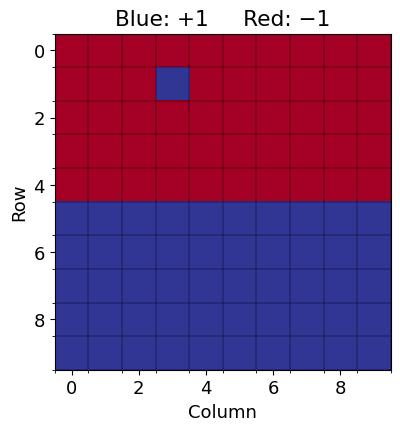

In [2]:
N = 10
spins = np.ones((N, N), dtype=int)
spins[:5, :] = -1
spins[1, 3] = 1

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(spins, cmap="RdYlBu", vmin=-1, vmax=1)
ax.set_xticks(np.arange(-0.5, N, 1), minor=True)
ax.set_yticks(np.arange(-0.5, N, 1), minor=True)
ax.grid(which="minor", color="black", linewidth=0.3)
ax.set(title="Blue: +1     Red: −1", xlabel="Column", ylabel="Row")
plt.show()

In [3]:
def total_energy(spins):
    n = spins.shape[0]
    energy = 0.0
    for i in range(n):
        for j in range(n):
            for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                neighbor = spins[(i + di) % n, (j + dj) % n]
                energy -= J * spins[i, j] * neighbor
    return energy / 2

print("Energy:", total_energy(spins))

Energy: -152.0


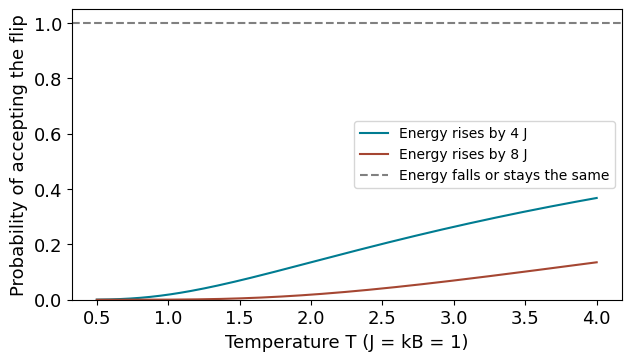

In [4]:
temperature_axis = np.linspace(0.5, 4.0, 150)
fig, ax = plt.subplots()
for cost, color in [(4 * J, "#007c91"), (8 * J, "#a54632")]:
    probability = np.exp(-cost / (KB * temperature_axis))
    ax.plot(temperature_axis, probability,
            color=color, label=f"Energy rises by {cost:g} J")
ax.axhline(1, color="gray", linestyle="--", label="Energy falls or stays the same")
ax.set(xlabel="Temperature T (J = kB = 1)",
       ylabel="Probability of accepting the flip", ylim=(0, 1.05))
ax.legend(fontsize=10)
plt.show()

In [5]:
@njit
def flip_energy(spins, i, j):
    n = spins.shape[0]
    neighbors = spins[(i - 1) % n, j] + spins[(i + 1) % n, j] + spins[i, (j - 1) % n] + spins[i, (j + 1) % n]
    return 2 * J * spins[i, j] * neighbors

print("Flip the isolated +1 spin:", flip_energy(spins, 1, 3))

Flip the isolated +1 spin: -8.0


In [6]:
@njit
def metropolis_step(spins, temperature, rng):
    i, j = rng.integers(0, spins.shape[0], size=2)
    delta_energy = flip_energy(spins, i, j)
    if delta_energy <= 0 or rng.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[i, j] *= -1
        return 1
    return 0

In [7]:
@njit
def advance_ising(spins, temperature, sweeps, rng):
    n = spins.shape[0]
    magnetization = np.empty(sweeps + 1)
    magnetization[0] = spins.mean()
    accepted = 0
    for sweep in range(1, sweeps + 1):
        for _ in range(n * n):
            accepted += metropolis_step(spins, temperature, rng)
        magnetization[sweep] = spins.mean()
    return (magnetization, accepted)


def run_ising(temperature, n, sweeps, seed):
    rng = np.random.default_rng(seed)
    spins = np.ones((n, n), dtype=int)
    magnetization, accepted = advance_ising(spins, temperature, sweeps, rng)
    return (spins, magnetization, accepted / (sweeps * n * n))

In [8]:
N = 24
SWEEPS = 400
SEED = 142
T = 2.0

final_spins, m_values, acceptance = run_ising(T, N, SWEEPS, SEED)
print(f"Attempted flips: {SWEEPS * N * N:,}")
print(f"Acceptance rate: {acceptance:.3f}")

Attempted flips: 230,400
Acceptance rate: 0.080


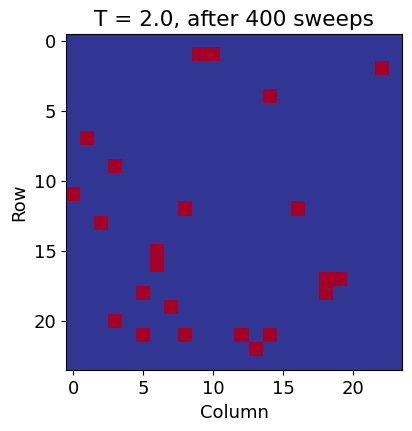

In [9]:
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.imshow(final_spins, cmap="RdYlBu", vmin=-1, vmax=1)
ax.set(title=f"T = {T}, after {SWEEPS} sweeps",
       xlabel="Column", ylabel="Row")
plt.show()

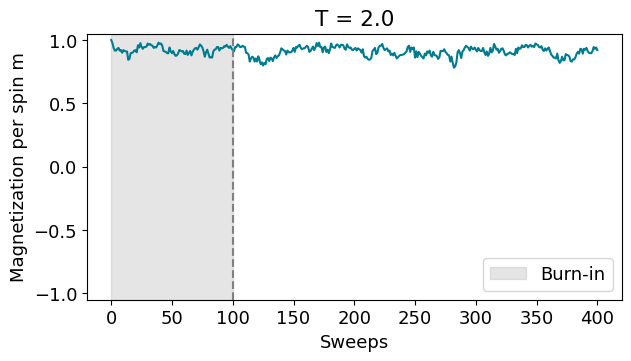

In [10]:
BURNIN = 100
sweep_axis = np.arange(SWEEPS + 1)

fig, ax = plt.subplots()
ax.plot(sweep_axis, m_values, color="#007c91")
ax.axvspan(0, BURNIN, color="gray", alpha=0.2, label="Burn-in")
ax.axvline(BURNIN, color="gray", linestyle="--")
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       title=f"T = {T}", ylim=(-1.05, 1.05))
ax.legend()
plt.show()

In [11]:
samples = m_values[BURNIN + 1:]
print(f"Mean m: {samples.mean():.3f}")
print(f"Standard deviation of m: {samples.std():.3f}")
print(f"Mean |m|: {np.abs(samples).mean():.3f}")

Mean m: 0.907
Standard deviation of m: 0.039
Mean |m|: 0.907


In [12]:
temperatures = [1.5, 2.269, 3.5]
runs = {}
for index, temperature in enumerate(temperatures):
    runs[temperature] = run_ising(temperature, N, SWEEPS, SEED + index)
    _, history, rate = runs[temperature]
    mean_abs_m = np.abs(history[BURNIN + 1:]).mean()
    print(f"T = {temperature:.3f}: mean |m| = {mean_abs_m:.3f}, "
          f"acceptance = {rate:.3f}")

T = 1.500: mean |m| = 0.987, acceptance = 0.013
T = 2.269: mean |m| = 0.593, acceptance = 0.208
T = 3.500: mean |m| = 0.081, acceptance = 0.542


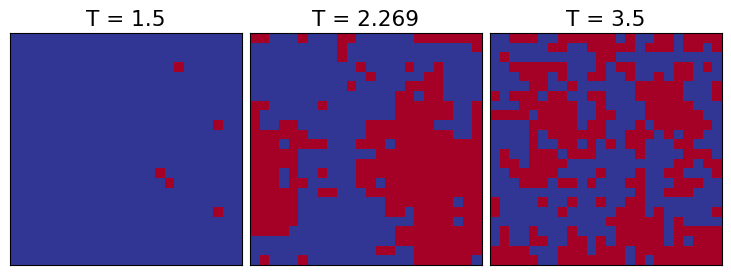

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 3.0))
for ax, temperature in zip(axes, temperatures):
    lattice, _, _ = runs[temperature]
    ax.imshow(lattice, cmap="RdYlBu", vmin=-1, vmax=1)
    ax.set(title=f"T = {temperature:g}", xticks=[], yticks=[])
plt.show()

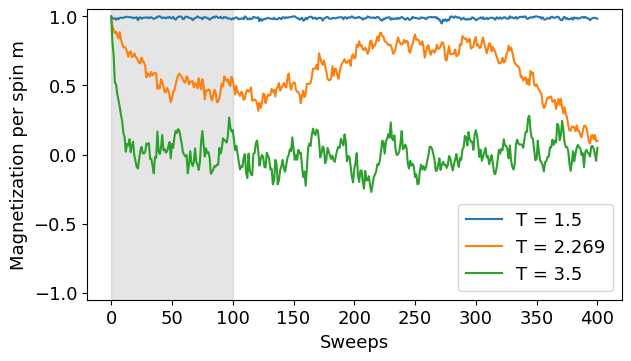

In [14]:
fig, ax = plt.subplots()
for temperature in temperatures:
    _, history, _ = runs[temperature]
    ax.plot(sweep_axis, history, label=f"T = {temperature:g}")
ax.axvspan(0, BURNIN, color="gray", alpha=0.2)
ax.set(xlabel="Sweeps", ylabel="Magnetization per spin m",
       ylim=(-1.05, 1.05))
ax.legend()
plt.show()

In [15]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Each entry is a separate simulation, with the same start and random seed.
temperature_grid = [1.0, 1.5, 2.0, 2.269, 2.5, 3.0, 3.5, 4.0]
saved_runs = [run_ising(temp, 64, 400, 142) for temp in temperature_grid]

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.3))
lattice_image = axes[0].imshow(saved_runs[0][0], cmap="RdYlBu", vmin=-1, vmax=1)
axes[0].set(xticks=[], yticks=[])
history_line, = axes[1].plot(saved_runs[0][1], color="#007c91")
axes[1].set(xlabel="Sweeps", ylabel="Magnetization per spin m", ylim=(-1.05, 1.05))

def show_temperature(index):
    lattice, history, rate = saved_runs[index]
    lattice_image.set_data(lattice)
    history_line.set_ydata(history)
    axes[0].set_title(f"T = {temperature_grid[index]:g}; final lattice")
    axes[1].set_title(f"Accepted: {rate:.1%}")
    return lattice_image, history_line

temperature_comparison = FuncAnimation(
    fig, show_temperature, frames=len(temperature_grid), interval=900, repeat=False)
temperature_html = temperature_comparison.to_jshtml(default_mode="once")
plt.close(fig)

In [16]:
display(HTML(temperature_html))